# Exploratory look at each data source

Raw files live in `data/raw`. `prepare.py` writes cleaned tables to `data/silver` and the joined tables to `data/gold`. Each section below is one source, a chart, and what it means for running a liquefaction plant.

**What the data says**

1. **Venture Global is now about 29% of U.S. LNG exports.** Plaquemines started in December 2024 and is already the second-largest Gulf terminal, behind only Sabine Pass.
2. **Exports dip about 10% below trend every summer.** June to September, when Lake Charles averages 27–29°C, is the weak stretch. That fits hot air cutting liquefaction capacity, and it is the first thing a monthly plan should account for.
3. **Price, storms, and terminal volume look stronger on paper than they are.** Correlations on levels mostly reflect the shared growth trend. On month-to-month changes, only terminal volume still tracks exports.
4. **Counting days and the calendar month beats the regression.** Forecasting the daily rate and the usual seasonal change misses by about 20 Bcf a month, 22% better than "same as last month".
5. **A simple sensor band catches about 79% of fault rows. The random forest is not clearly better.** Both mostly miss faults 3, 9, and 15, as the benchmark literature reports.
6. **The normal class is the bottleneck.** The models learn "normal" from one 25-hour run, and they raise false alarms on a second normal run. More normal history is the cheapest improvement.

In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import pandas as pd

RAW = Path("data/raw")
SILVER = Path("data/silver")
GOLD = Path("data/gold")

# One chart style for the whole notebook. Colors are fixed per role, never cycled.
BLUE, ORANGE, AQUA, GRAY, LIGHT_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#c9c8c2"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
})


def thousands(axis):
    axis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))


def percent(axis):
    axis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

## Sensors: Tennessee Eastman

Each file is one run of a chemical plant, used here as the historian. `d00` is normal operation. `d01` through `d21` are faults.

There are two sets of runs. In the training runs `dXX.dat` the fault is already on when recording starts, so every row is faulty. In the test runs `dXX_te.dat` the plant runs normally for 160 steps (8 hours) and then the fault is switched on. The model trains on the first set and is scored on the second, so it is always judged on runs it has never seen. One step is 3 minutes.

In [32]:
shapes = []
for path in sorted((RAW / "tep").glob("d*.dat")):
    frame = pd.read_csv(path, sep=r"\s+", header=None)
    shapes.append({"file": path.name, "rows": frame.shape[0], "columns": frame.shape[1]})

pd.DataFrame(shapes).head(4)

,file,rows,columns
0,d00.dat,52,500
1,d00_te.dat,960,52
2,d01.dat,480,52
3,d01_te.dat,960,52


Fault descriptions for the Tennessee Eastman files:

| File(s) | Description |
|---|---|
| d00 | Nothing. Normal operation. |
| d01 | Sudden change in the feed mix (A/C ratio). |
| d02 | Sudden change in the amount of component B in the feed. |
| d03 | Sudden change in the D feed temperature. |
| d04 | Sudden change in reactor cooling-water temperature. |
| d05 | Sudden change in condenser cooling-water temperature. |
| d06 | Loss of the A feed. |
| d07 | Loss of pressure in the C feed header. |
| d08 | Random swings in the A, B, and C feed composition. |
| d09 | Random swings in the D feed temperature. |
| d10 | Random swings in the C feed temperature. |
| d11 | Random swings in reactor cooling-water temperature. |
| d12 | Random swings in condenser cooling-water temperature. |
| d13 | Slow drift in the reaction speed. |
| d14 | Reactor cooling-water valve sticks. |
| d15 | Condenser cooling-water valve sticks. |
| d16–d20 | Unknown faults. The benchmark does not say what broke. |
| d21 | A feed valve is stuck at its normal position. |

The 52 columns are 41 measurements (`XMEAS`) and 11 valve or flow settings (`XMV`). The names below are used to label the charts.

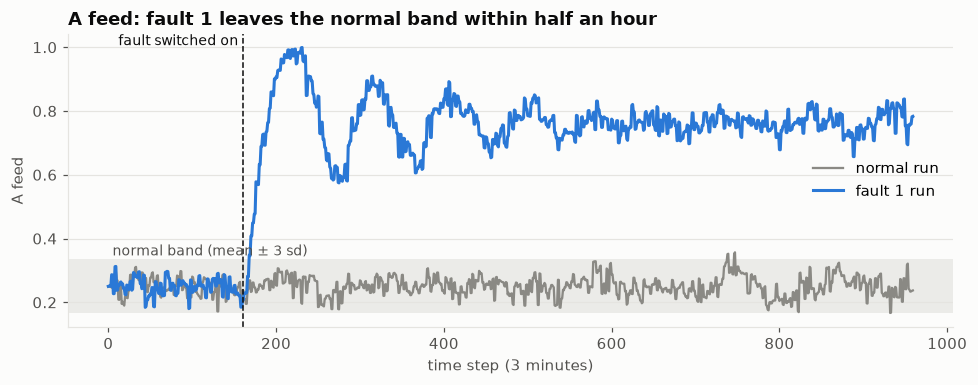

In [33]:
TAGS = (
    ["A feed", "D feed", "E feed", "A and C feed", "Recycle flow", "Reactor feed rate",
     "Reactor pressure", "Reactor level", "Reactor temperature", "Purge rate",
     "Separator temperature", "Separator level", "Separator pressure", "Separator underflow",
     "Stripper level", "Stripper pressure", "Stripper underflow", "Stripper temperature",
     "Stripper steam flow", "Compressor work", "Reactor cooling-water outlet temp",
     "Condenser cooling-water outlet temp"]
    + [f"Reactor feed analysis {c}" for c in "ABCDEF"]
    + [f"Purge gas analysis {c}" for c in "ABCDEFGH"]
    + [f"Product analysis {c}" for c in "DEFGH"]
    + ["D feed valve", "E feed valve", "A feed valve", "A and C feed valve",
       "Compressor recycle valve", "Purge valve", "Separator liquid valve",
       "Stripper product valve", "Stripper steam valve", "Reactor cooling-water valve",
       "Condenser cooling-water valve"]
)
TAG = {f"x{i}": name for i, name in enumerate(TAGS, start=1)}


def read_run(path):
    frame = pd.read_csv(path, sep=r"\s+", header=None)
    if frame.shape[1] > frame.shape[0]:
        frame = frame.T.reset_index(drop=True)
    frame.columns = [f"x{i}" for i in range(1, frame.shape[1] + 1)]
    return frame


normal_train = read_run(RAW / "tep" / "d00.dat")
normal = read_run(RAW / "tep" / "d00_te.dat")
fault1 = read_run(RAW / "tep" / "d01_te.dat")
tag = "x1"
low = normal_train[tag].mean() - 3 * normal_train[tag].std()
high = normal_train[tag].mean() + 3 * normal_train[tag].std()

fig, ax = plt.subplots()
ax.axhspan(low, high, color=GRID, alpha=0.7, lw=0)
ax.plot(normal[tag], color=GRAY, lw=1.5, label="normal run")
ax.plot(fault1[tag], color=BLUE, label="fault 1 run")
ax.axvline(160, color=INK, lw=1, ls="--")
ax.text(155, ax.get_ylim()[1], "fault switched on", va="top", ha="right", color=INK, fontsize=9)
ax.text(5, high, "normal band (mean ± 3 sd)", va="bottom", color=MUTED, fontsize=9)
ax.set_title(f"{TAG[tag]}: fault 1 leaves the normal band within half an hour")
ax.set_xlabel("time step (3 minutes)")
ax.set_ylabel(TAG[tag])
ax.legend(loc="center right")
plt.tight_layout()

Before step 160 both runs sit inside the band. After the feed-mix change, fault 1 moves the A-feed reading out of the band and keeps it out. That is the case a simple alarm handles well. Several other faults never move a single tag this far, which is why a rule on one tag is not enough.

## National LNG exports

EIA series N9133US2, liquefied U.S. natural gas exports. Charts show billion cubic feet (Bcf) per month: 1 Bcf is 1,000 million cubic feet.

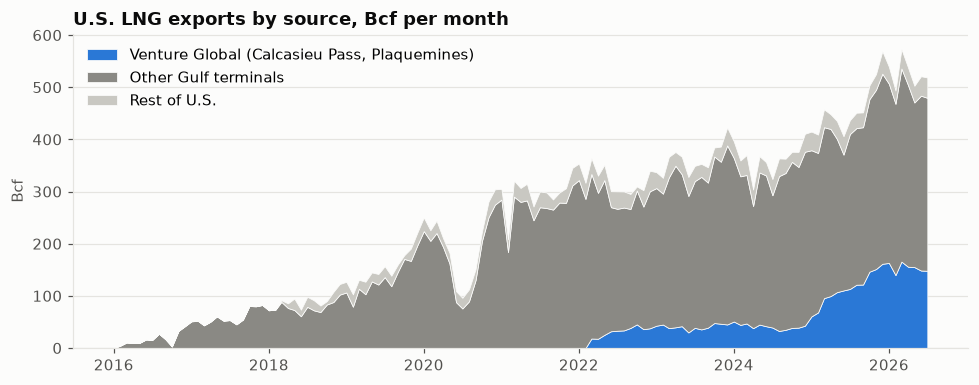

In [34]:
exports = pd.read_csv(RAW / "lng_exports.csv", parse_dates=["month"])
gulf = pd.read_csv(RAW / "gulf_lng_exports.csv", parse_dates=["month"])
by_terminal = gulf.pivot_table(index="month", columns="terminal", values="exports_mmcf", aggfunc="sum").fillna(0)

volume = exports.set_index("month")["exports_mmcf"].to_frame("total")
volume = volume.join(by_terminal, how="left").fillna(0).loc["2016":] / 1000
venture_global = volume["Calcasieu Pass"] + volume["Plaquemines"]
other_gulf = volume[by_terminal.columns].sum(axis=1) - venture_global
rest_of_us = (volume["total"] - venture_global - other_gulf).clip(lower=0)

fig, ax = plt.subplots()
ax.stackplot(
    volume.index, venture_global, other_gulf, rest_of_us,
    colors=[BLUE, GRAY, LIGHT_GRAY], edgecolor="#fcfcfb", linewidth=0.5,
    labels=["Venture Global (Calcasieu Pass, Plaquemines)", "Other Gulf terminals", "Rest of U.S."],
)
ax.set_title("U.S. LNG exports by source, Bcf per month")
ax.set_ylabel("Bcf")
thousands(ax.yaxis)
ax.legend(loc="upper left")
plt.tight_layout()

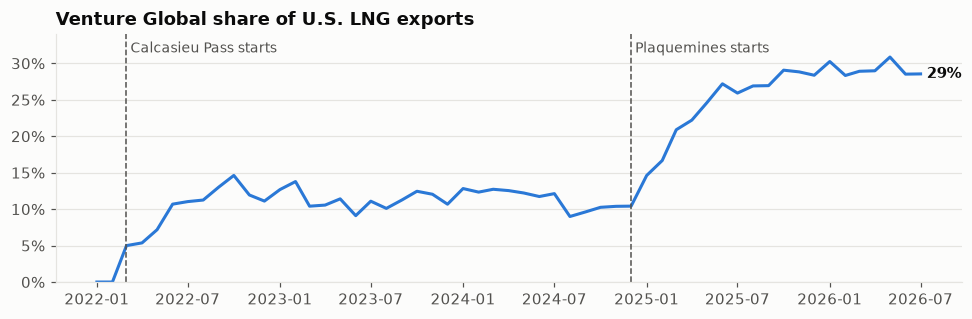

In [35]:
share = (venture_global / volume["total"]).loc["2022":]

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(share.index, share, color=BLUE)
for start, name in [("2022-03", "Calcasieu Pass starts"), ("2024-12", "Plaquemines starts")]:
    ax.axvline(pd.Timestamp(start), color=MUTED, lw=1, ls="--")
    ax.text(pd.Timestamp(start), 0.33, f" {name}", color=MUTED, fontsize=9, va="top")
ax.annotate(f"{share.iloc[-1]:.0%}", (share.index[-1], share.iloc[-1]), xytext=(4, 0),
            textcoords="offset points", va="center", color=INK, fontweight="bold")
ax.set_ylim(0, 0.34)
percent(ax.yaxis)
ax.set_title("Venture Global share of U.S. LNG exports")
plt.tight_layout()

U.S. exports were close to zero until Sabine Pass opened in February 2016. They now run above 500 Bcf a month. The one large drop, in mid-2020, is the pandemic, when buyers cancelled cargoes. Venture Global went from nothing in early 2022 to about 29% of the national total. Most of the recent jump is Plaquemines. A 1% gain in Venture Global train output is now worth about 1.5 Bcf a month of national supply, so availability on these trains matters at the national level.

## Gulf terminals

Monthly liquefied-gas exports from seven Gulf terminals. This stands in for the ship-and-terminal schedule. Sabine Pass, Cameron, Calcasieu Pass, and Plaquemines are in Louisiana. Corpus Christi, Freeport, and Golden Pass are in Texas.

A cumulative total would favor the oldest terminals. The last 12 months show where volume comes from now.

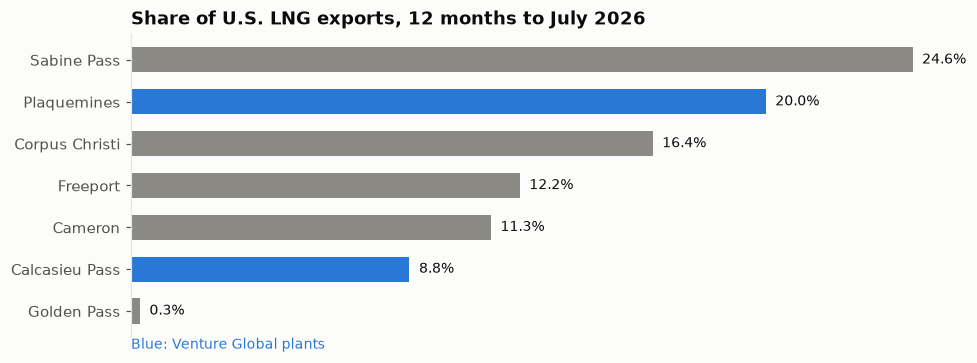

In [36]:
last_year = by_terminal.loc[by_terminal.index >= by_terminal.index.max() - pd.DateOffset(months=11)]
recent = (last_year.sum() / exports.set_index("month").loc[last_year.index, "exports_mmcf"].sum()).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [BLUE if name in ("Calcasieu Pass", "Plaquemines") else GRAY for name in recent.index]
ax.barh(recent.index, recent, color=colors, height=0.6)
for name, value in recent.items():
    ax.text(value + 0.003, name, f"{value:.1%}", va="center", color=INK, fontsize=9)
ax.grid(False)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_title(f"Share of U.S. LNG exports, 12 months to {last_year.index.max():%B %Y}")
ax.text(0, -0.9, "Blue: Venture Global plants", color=BLUE, fontsize=9, transform=ax.get_yaxis_transform())
plt.tight_layout()

Sabine Pass is still the largest terminal at about a quarter of U.S. exports. Plaquemines, less than two years old, is second at about 20%. Calcasieu Pass adds about 9%. Golden Pass started in April 2026 and is still ramping. Each new plant reaches a large share fast, which is why carrying screens and lessons from Calcasieu Pass to Plaquemines and CP2 is worth doing.

## Gas supply: Henry Hub

Monthly Henry Hub price, dollars per million Btu. This stands in for the cost and availability of feed gas.

In [37]:
price = pd.read_csv(RAW / "henry_hub.csv", parse_dates=["month"])
price["henry_hub"].describe().round(2)

count    357.00
mean       4.09
std        2.10
min        1.49
25%        2.62
50%        3.38
75%        5.15
max       13.42
Name: henry_hub, dtype: float64

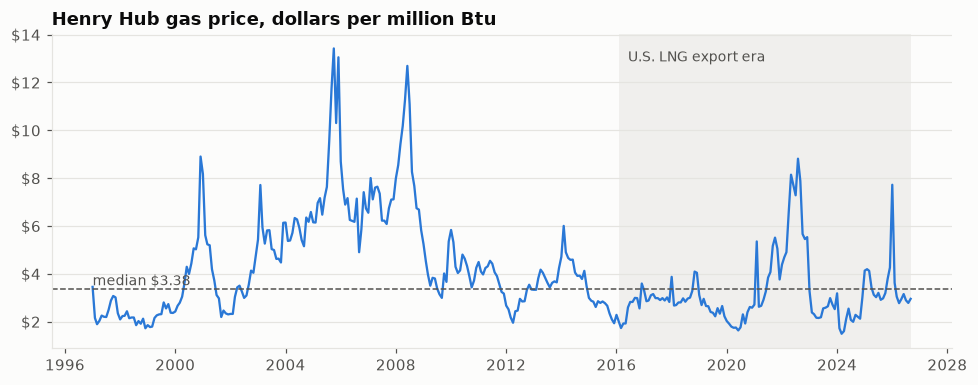

In [38]:
fig, ax = plt.subplots()
ax.plot(price["month"], price["henry_hub"], color=BLUE, lw=1.5)
ax.axhline(price["henry_hub"].median(), color=MUTED, lw=1, ls="--")
ax.text(price["month"].iloc[0], price["henry_hub"].median(), f"median ${price['henry_hub'].median():.2f}",
        va="bottom", color=MUTED, fontsize=9)
ax.axvspan(pd.Timestamp("2016-02"), price["month"].max(), color=GRID, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2016-06"), ax.get_ylim()[1] * 0.95, "U.S. LNG export era", color=MUTED, fontsize=9, va="top")
ax.set_title("Henry Hub gas price, dollars per million Btu")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()

The price spiked above $12 in 2005 and 2008, and above $8 in 2022. Since 2016 it has mostly stayed between $2 and $4, while exports grew more than tenfold. The terminals run on long-term contracts, so feed gas price shapes margins more than it shapes monthly volume. Its use in a volume forecast is weak, as the planning table confirms below.

## Ambient weather: Lake Charles

Monthly average temperature at the Lake Charles airport, the weather station nearest Calcasieu Pass. Values are degrees Celsius.

In [39]:
weather = pd.read_csv(RAW / "lake_charles_weather.csv", parse_dates=["DATE"]).dropna(subset=["TAVG"])
weather["calendar_month"] = weather["DATE"].dt.month
climate = weather.groupby("calendar_month")["TAVG"].agg(["mean", "min", "max"])
climate.round(1).T

calendar_month,1,2,3,4,5,6,7,8,9,10,11,12
mean,11.5,13.6,17.3,20.6,24.5,27.7,28.6,28.9,26.7,21.7,16.3,12.8
min,7.9,9.0,14.0,17.6,22.8,26.3,27.6,27.5,24.8,19.4,13.4,8.1
max,15.3,18.1,21.5,22.6,26.6,29.5,29.9,31.8,28.8,24.4,20.2,18.0


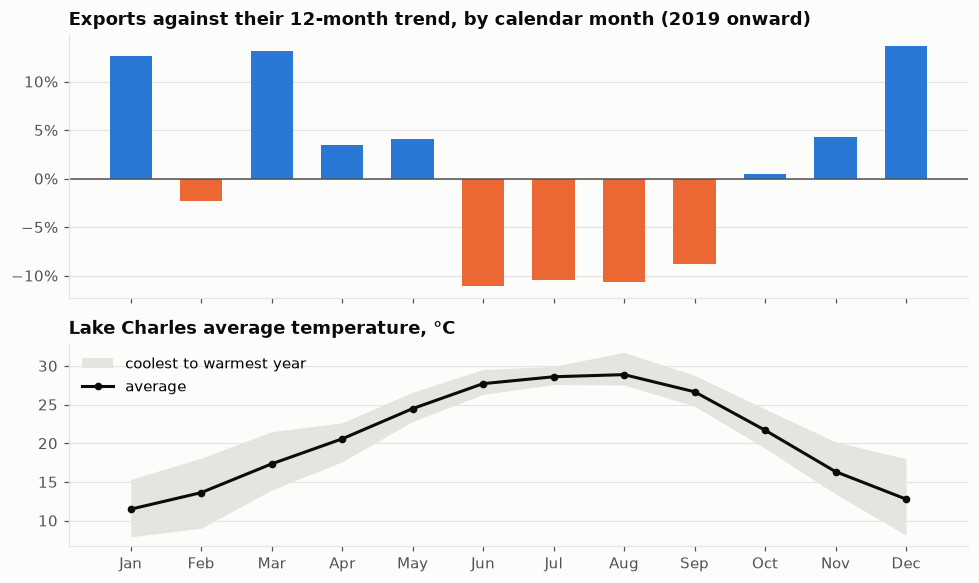

In [40]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Exports divided by their centered 12-month average. This removes the growth trend
# and leaves the seasonal pattern. Start in 2019, once several terminals were running.
trend_ratio = (volume["total"] / volume["total"].rolling(12, center=True).mean()).loc["2019":].dropna()
seasonal = trend_ratio.groupby(trend_ratio.index.month).mean() - 1

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=[1.3, 1])
top.bar(seasonal.index, seasonal, color=[ORANGE if value < 0 else BLUE for value in seasonal], width=0.6)
top.axhline(0, color=MUTED, lw=1)
percent(top.yaxis)
top.set_title("Exports against their 12-month trend, by calendar month (2019 onward)")

bottom.fill_between(climate.index, climate["min"], climate["max"], color=GRID, lw=0, label="coolest to warmest year")
bottom.plot(climate.index, climate["mean"], color=INK, marker="o", ms=4, label="average")
bottom.set_title("Lake Charles average temperature, °C")
bottom.set_xticks(range(1, 13), month_names)
bottom.legend(loc="upper left")
plt.tight_layout()

Lake Charles averages about 11°C in January and 29°C in August. U.S. exports follow the temperature: June to September run about 9–11% below trend, and December, January, and March run 11–14% above it. Two things push in that direction. Liquefaction makes less LNG in hot air, because compressors and air coolers lose capacity as ambient temperature rises. Planned maintenance is also usually scheduled outside winter, when demand is highest. February is lower partly because it has fewer days.

For a monthly plan this is the biggest regular swing in the data. A forecast that ignores the calendar month will be too high every summer.

## Louisiana storms

NOAA storm files cover the whole country. This keeps Louisiana, which is the weather risk around the Gulf terminals.

181,223 U.S. events, 3,269 in Louisiana


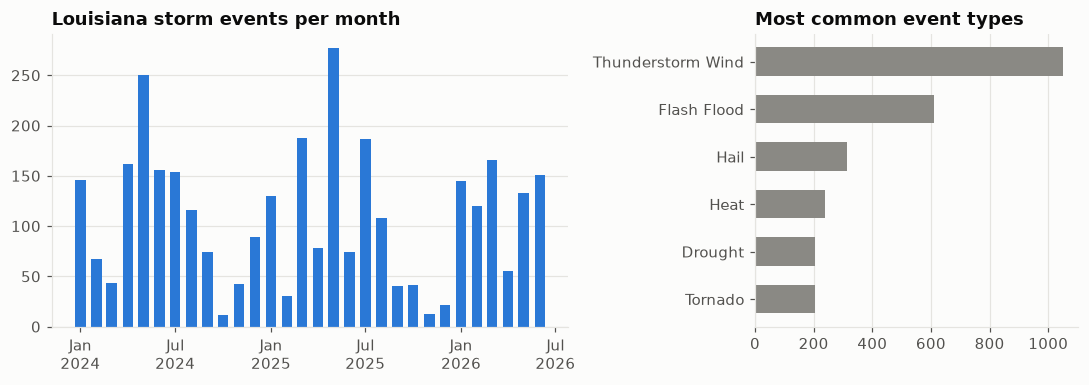

In [41]:
# NOAA reissues each year with a newer creation date. Keep only the newest file per year.
newest = {path.name.split("_c")[0]: path for path in sorted((RAW / "noaa").glob("*.csv.gz"))}
storms = pd.concat(
    pd.read_csv(path, usecols=["STATE", "BEGIN_YEARMONTH", "EVENT_TYPE"]) for path in newest.values()
)
louisiana = storms[storms["STATE"].str.strip().str.upper() == "LOUISIANA"].copy()
louisiana["month"] = pd.to_datetime(louisiana["BEGIN_YEARMONTH"].astype(str), format="%Y%m")
print(f"{len(storms):,} U.S. events, {len(louisiana):,} in Louisiana")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), width_ratios=[1.6, 1])
monthly_storms = louisiana.groupby("month").size()
left.bar(monthly_storms.index, monthly_storms.values, width=20, color=BLUE)
left.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
left.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
left.set_title("Louisiana storm events per month")

types = louisiana["EVENT_TYPE"].value_counts().head(6).sort_values()
right.barh(types.index, types.values, color=GRAY, height=0.6)
right.grid(axis="x")
right.grid(axis="y", visible=False)
right.set_title("Most common event types")
plt.tight_layout()

About 3,300 of the national events are in Louisiana. Thunderstorm wind, flash flood, and hail are the common types. Counts are highest in spring and early summer, with May the peak, and lowest in October and November. A count treats a hailstorm and a hurricane the same, so it is a weak feature for volume. A better risk signal would weight events by type and distance from the terminals.

## Maintenance

Microsoft predictive-maintenance logs: work orders and component failures. The sample runs from mid-2014 into early 2016, so it does not share months with the 2024–2026 export table.

3,286 work orders, 761 failures
from 2014-06-01 to 2016-01-01


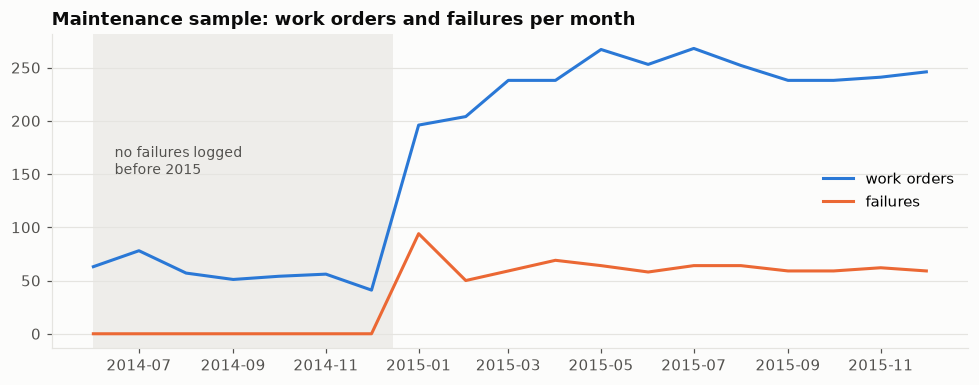

In [42]:
work = pd.read_csv(RAW / "pdm" / "PdM_maint.csv", parse_dates=["datetime"])
failures = pd.read_csv(RAW / "pdm" / "PdM_failures.csv", parse_dates=["datetime"])
print(f"{len(work):,} work orders, {len(failures):,} failures")
print(f"from {work['datetime'].min().date()} to {work['datetime'].max().date()}")

maintenance = pd.read_csv(GOLD / "maintenance.csv", parse_dates=["month"])
# January 2016 holds a single day of records, so it is left off the chart.
maintenance = maintenance[maintenance["month"] < "2016-01-01"]
fig, ax = plt.subplots()
ax.plot(maintenance["month"], maintenance["maintenance_jobs"], color=BLUE, label="work orders")
ax.plot(maintenance["month"], maintenance["failures"], color=ORANGE, label="failures")
ax.axvspan(maintenance["month"].min(), pd.Timestamp("2014-12-15"), color=GRID, alpha=0.6, lw=0)
ax.text(pd.Timestamp("2014-06-15"), 150, "no failures logged\nbefore 2015", color=MUTED, fontsize=9)
ax.set_title("Maintenance sample: work orders and failures per month")
ax.legend(loc="center right")
plt.tight_layout()

Work orders outnumber failures by about four to one: 3,286 jobs and 761 failures. The log has a gap that matters for modeling: 2014 has work orders but no failures at all, then failures start in January 2015. That looks like a change in what was recorded, not a year with nothing broken. A failure model should train on 2015 only, or it will learn that 2014 conditions never fail.

Failures are the rare event a downtime-risk classifier has to predict, with the same class imbalance as the sensor faults. Because these months end in 2016, they serve as a failure example. They cannot explain why 2024–2026 exports changed.

## Alerts on the sensor table

`prepare.py` stacks every run into `data/silver/sensors.csv`. A row is flagged when any of the 52 measurements leaves the normal-operation band, mean ± 3 standard deviations on the normal training run `d00.dat`.

In [43]:
sensors = pd.read_csv(SILVER / "sensors.csv")
alerts = pd.read_csv(GOLD / "alerts.csv")
print(f"{len(sensors):,} sensor rows")
alerts.groupby(["split", "is_fault"])["outside_limits"].mean().rename("share flagged").round(3).to_frame()

31,700 sensor rows


share flagged
split is_fault               
test  0                 0.182
      1                 0.792
train 0                 0.094
      1                 0.739

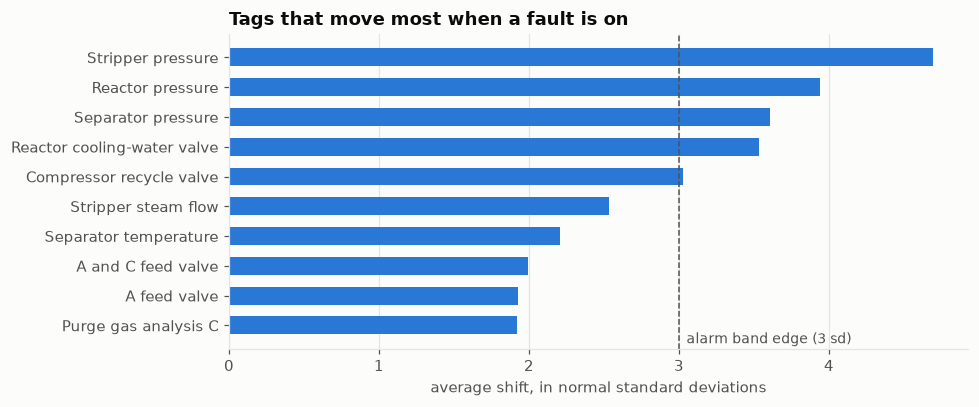

In [44]:
# Tags have different units, so compare the fault shift in normal standard deviations.
train = sensors[sensors["split"] == "train"]
features = [column for column in sensors.columns if column.startswith("x")]
normal_rows = train.loc[train["is_fault"] == 0, features]
shift = ((train.loc[train["is_fault"] == 1, features].mean() - normal_rows.mean()) / normal_rows.std()).abs()
top = shift.sort_values().tail(10)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh([TAG[column] for column in top.index], top, color=BLUE, height=0.6)
ax.axvline(3, color=MUTED, lw=1, ls="--")
ax.text(3.05, -0.6, "alarm band edge (3 sd)", color=MUTED, fontsize=9)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Tags that move most when a fault is on")
ax.set_xlabel("average shift, in normal standard deviations")
plt.tight_layout()

In the training runs, normal operation is 500 rows and each fault is 480 rows, so fault rows outnumber normal rows about 20 to 1. `model.py` weights the two classes because of that count.

Pressures (stripper, reactor, separator) and the reactor cooling-water valve move most, and only a few tags pass the 3 sd band edge on average. An engineer would watch those tags first. Most of the 52 tags barely move, so most faults show up as small shifts across several tags, not one big jump.

The band flags about 9% of the normal training rows it was fitted on and about 18% of normal test rows it never saw. On a new day of normal operation it raises almost twice as many false alarms. One 25-hour run does not capture the full normal range.

## Monthly planning table

`monthly.csv` keeps only months where exports, Henry Hub, Lake Charles temperature, Louisiana storms, and Gulf terminal volume all exist.

In [45]:
monthly = pd.read_csv(GOLD / "monthly.csv", parse_dates=["month"])
columns = ["exports_mmcf", "henry_hub", "temp_c", "storms", "terminal_mmcf"]
print(f"{monthly['month'].min():%Y-%m} to {monthly['month'].max():%Y-%m}, {len(monthly)} months")

# Two growing series always look correlated. Month-to-month changes show whether they move together.
pd.DataFrame({
    "levels": monthly[columns].corr()["exports_mmcf"],
    "monthly changes": monthly[columns].diff().corr()["exports_mmcf"],
}).drop("exports_mmcf").round(2)

2024-01 to 2026-06, 30 months


,levels,monthly changes
henry_hub,0.61,0.20
temp_c,-0.24,-0.25
storms,-0.12,0.20
terminal_mmcf,1.00,0.99


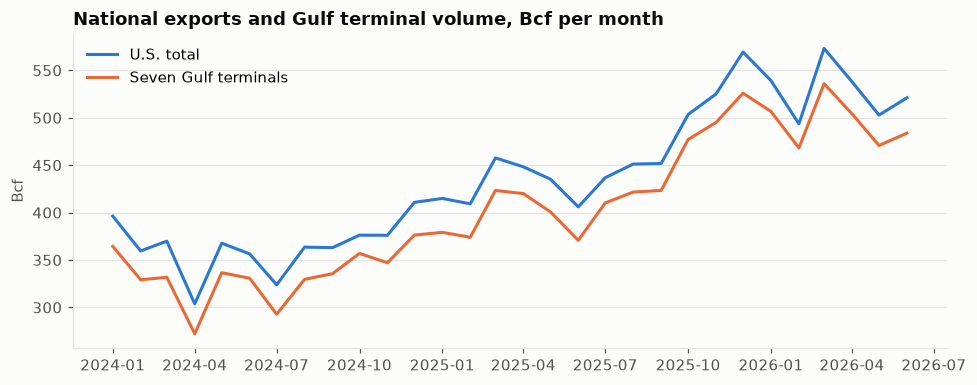

In [46]:
fig, ax = plt.subplots()
ax.plot(monthly["month"], monthly["exports_mmcf"] / 1000, color=BLUE, label="U.S. total")
ax.plot(monthly["month"], monthly["terminal_mmcf"] / 1000, color=ORANGE, label="Seven Gulf terminals")
ax.set_title("National exports and Gulf terminal volume, Bcf per month")
ax.set_ylabel("Bcf")
ax.legend(loc="upper left")
plt.tight_layout()

On levels, Henry Hub looks linked to exports (0.61), because both rose over 2024–2026. On month-to-month changes, that drops to 0.20. Storm counts even flip sign, from -0.12 to +0.20, so there is no stable storm signal in 30 months. Temperature is the one outside input that holds up on changes (about -0.25): hotter months export less, which fits the summer dip. Gulf terminal volume still tracks exports almost exactly on changes, because it is most of the same gas. That makes it a reconciliation check, not a forecasting input: it is not known before the month ends.

## Volume gap

National exports minus the Gulf terminal total. The remainder is LNG that left from other places, including Cove Point and Elba Island.

count    91.000
mean      0.095
std       0.036
min       0.025
25%       0.075
50%       0.090
75%       0.104
max       0.229
dtype: float64

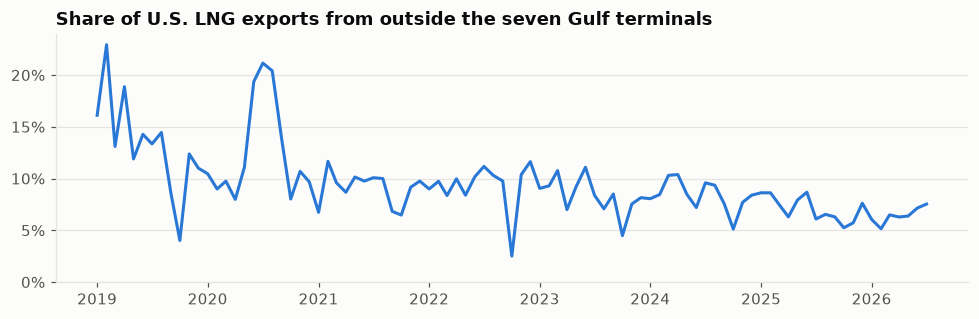

In [47]:
gap = pd.read_csv(GOLD / "volume_gap.csv", parse_dates=["month"])
gap = gap[gap["month"] >= "2019-01-01"]
gap_share = gap["gap_mmcf"] / gap["exports_mmcf"]

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(gap["month"], gap_share, color=BLUE)
percent(ax.yaxis)
ax.set_ylim(0, None)
ax.set_title("Share of U.S. LNG exports from outside the seven Gulf terminals")
plt.tight_layout()
gap_share.describe().round(3)

Since 2019 the non-Gulf share has fallen from about 10–15% to about 6–8% as the Gulf terminals grew. The 2020 spike is the pandemic: cancelled cargoes hit the Gulf terminals harder than the smaller East Coast ones. Outside that, the gap is small and steady. This is the same pattern a measurement team checks at a plant: a small, stable gap is normal, and a sudden jump in the gap points to a meter or reporting problem.

## Model outputs

Both models are scored on data they never trained on, and each is compared with a simple method it has to beat.

| Model | Predicts | Compared with | Scored on |
|---|---|---|---|
| Fault detection | Is this sensor row normal or faulty? | Rule: any tag outside the normal band | Every row of the 22 test runs |
| Export forecast | Next month's U.S. LNG exports | Same as last month | The last 24 months, each forecast made only from earlier months |

### Fault detection: actual against predicted

Each table counts test rows. Rows are what really happened, and columns are what the method said.

In [48]:
from sklearn.metrics import recall_score

predictions = pd.read_csv(GOLD / "fault_predictions.csv")
actual = predictions["is_fault"].map({0: "actual normal", 1: "actual fault"})
tables = {
    name: pd.crosstab(actual, predictions[column].map({0: "said normal", 1: "said fault"}), rownames=[None], colnames=[None])
    .loc[["actual normal", "actual fault"], ["said normal", "said fault"]]
    for name, column in [("rule", "rule_predicted"), ("random forest", "model_predicted")]
}
pd.concat(tables, axis=1)

rule            random forest           
              said normal said fault   said normal said fault
actual normal        3535        785          3120       1200
actual fault         3486      13314          2900      13900

In [49]:
summary = pd.DataFrame({
    name: {
        "faults caught": recall_score(predictions["is_fault"], predictions[column]),
        "normal rows cleared": recall_score(predictions["is_fault"], predictions[column], pos_label=0),
    }
    for name, column in [("rule", "rule_predicted"), ("random forest", "model_predicted")]
})
summary.round(3)

,rule,random forest
faults caught,0.792,0.827
normal rows cleared,0.818,0.722


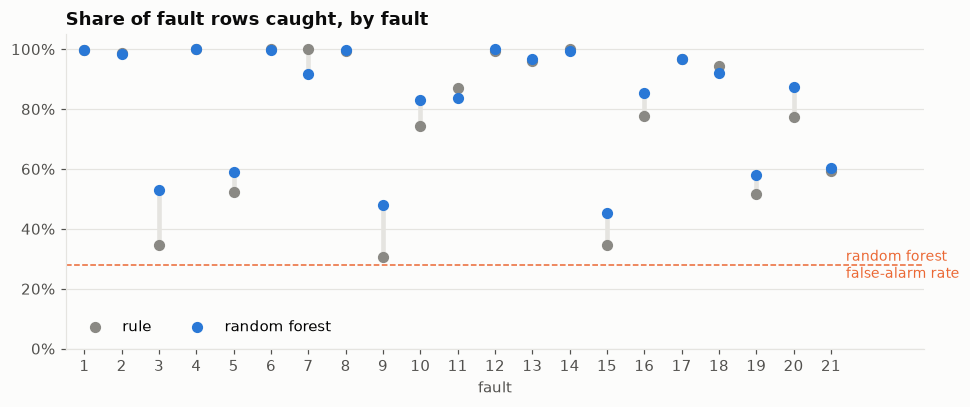

In [50]:
faulty = predictions[predictions["is_fault"] == 1]
caught = faulty.groupby("fault_id")[["rule_predicted", "model_predicted"]].mean()
false_alarms = predictions.loc[predictions["is_fault"] == 0, "model_predicted"].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.vlines(caught.index, caught.min(axis=1), caught.max(axis=1), color=GRID, lw=3)
ax.scatter(caught.index, caught["rule_predicted"], color=GRAY, s=40, zorder=3, label="rule")
ax.scatter(caught.index, caught["model_predicted"], color=BLUE, s=40, zorder=3, label="random forest")
ax.axhline(false_alarms, color=ORANGE, lw=1, ls="--")
ax.text(21.4, false_alarms, "random forest\nfalse-alarm rate", color=ORANGE, fontsize=9, va="center")
ax.set_xticks(caught.index)
ax.set_xlim(0.5, 23.5)
ax.set_ylim(0, 1.05)
percent(ax.yaxis)
ax.set_title("Share of fault rows caught, by fault")
ax.set_xlabel("fault")
ax.legend(loc="lower left", ncols=2)
plt.tight_layout()

Of the 4,320 normal test rows, the rule clears about 82% and the random forest about 72%. Of the 16,800 fault rows, the rule catches about 79% and the random forest about 83%. The random forest trades more false alarms for a few more catches.

Faults 1, 2, 4, 6, 8, 12, 13, 14, and 17 are caught almost every time by both methods. Faults 3, 9, and 15 stay at 30–55%, not far above the rate at which the model flags normal rows, so in practice they are not detected. The literature on this benchmark reports the same three. The random forest gains most on 3, 9, 10, 15, 16, and 20, but part of that gain is just firing more often. The rule is better on 7 and 18.

The next step is not a bigger model. It is more normal history, so both methods learn what a normal day looks like, then a check that an alert holds for several steps before anyone is called.

### Export forecast: actual against predicted

The EDA points to three fixes, each a step on the one before:

1. **Same daily rate.** Months have 28 to 31 days, so a 31-day month exports more at the same plant rate. Forecast the daily rate, then multiply by the days in the coming month.
2. **Calendar-month change.** Exports dip every summer and rise every winter. Multiply the daily rate by the median change into that calendar month since 2019. The median keeps the 2020 pandemic months from dominating.
3. **Average of the two.** The calendar-month pattern is real but noisy, with only seven years per month. Averaging it with step 1 uses half of the seasonal change. Fixed equal weights need no tuning, so nothing is fitted to the test months.

Each month in the test window is forecast from earlier months only, the way the plan would be made.

In [51]:
forecast = pd.read_csv(GOLD / "volume_forecast.csv", parse_dates=["month"])
methods = {
    "same_as_last_month": "Same as last month (baseline)",
    "same_daily_rate": "1. Same daily rate",
    "calendar_month": "2. Daily rate + calendar-month change",
    "forecast": "3. Average of 1 and 2 (final)",
}
miss = forecast[list(methods)].sub(forecast["actual"], axis=0).abs()
scores = pd.DataFrame({
    "mean miss, Bcf": miss.mean() / 1000,
    "mean miss, %": miss.div(forecast["actual"], axis=0).mean() * 100,
}).rename(index=methods)
scores["vs baseline"] = (scores["mean miss, Bcf"] / scores["mean miss, Bcf"].iloc[0] - 1) * 100
scores.round(1)

,"mean miss, Bcf","mean miss, %",vs baseline
Same as last month (baseline),25.3,5.3,0.0
1. Same daily rate,21.4,4.6,-15.6
2. Daily rate + calendar-month change,22.8,5.0,-9.8
3. Average of 1 and 2 (final),19.7,4.2,-22.2


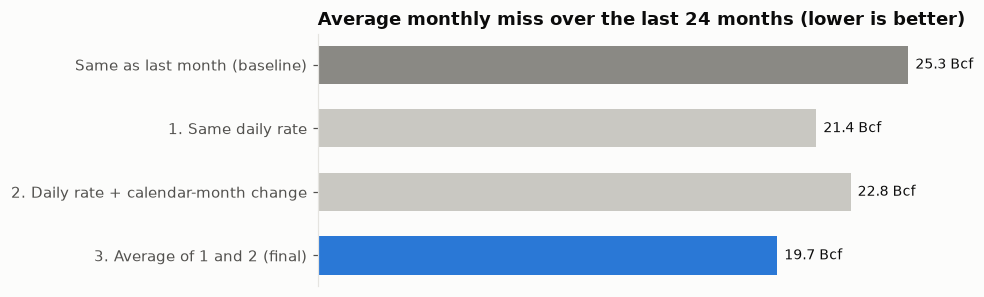

In [52]:
fig, ax = plt.subplots(figsize=(9, 2.8))
labels = list(scores.index)[::-1]
values = scores["mean miss, Bcf"][::-1]
colors = [BLUE if "final" in label else (GRAY if "baseline" in label else LIGHT_GRAY) for label in labels]
ax.barh(labels, values, color=colors, height=0.6)
for label, value in zip(labels, values):
    ax.text(value + 0.3, label, f"{value:.1f} Bcf", va="center", color=INK, fontsize=9)
ax.grid(False)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_title(f"Average monthly miss over the last {len(forecast)} months (lower is better)")
plt.tight_layout()

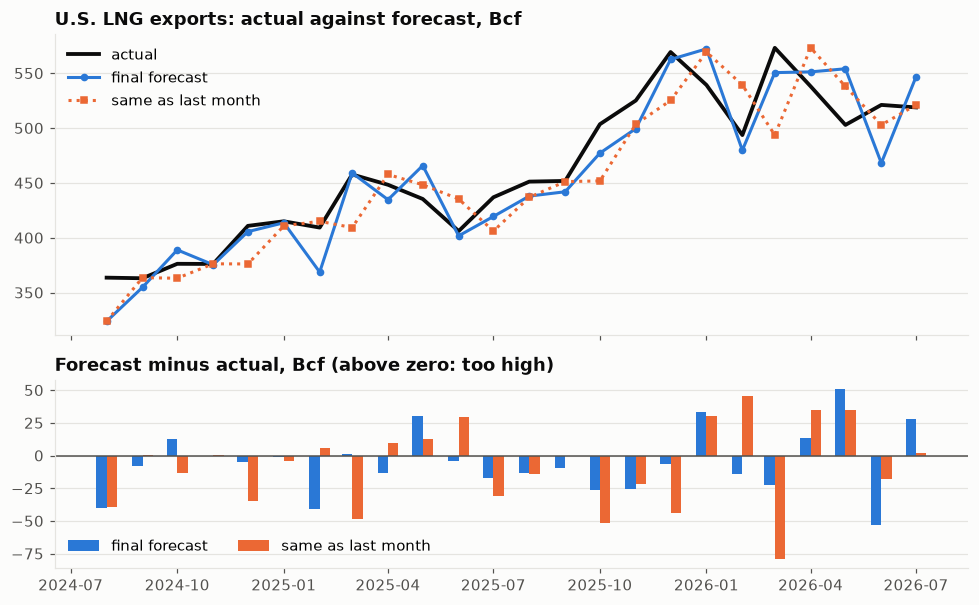

In [53]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, height_ratios=[1.6, 1])
top.plot(forecast["month"], forecast["actual"] / 1000, color=INK, lw=2.5, label="actual")
top.plot(forecast["month"], forecast["forecast"] / 1000, color=BLUE, marker="o", ms=4, label="final forecast")
top.plot(forecast["month"], forecast["same_as_last_month"] / 1000, color=ORANGE, ls=":", marker="s", ms=4, label="same as last month")
top.set_title("U.S. LNG exports: actual against forecast, Bcf")
top.legend(loc="upper left")

width = pd.Timedelta(days=9)
bottom.bar(forecast["month"] - width / 2, (forecast["forecast"] - forecast["actual"]) / 1000, width=width, color=BLUE, label="final forecast")
bottom.bar(forecast["month"] + width / 2, (forecast["same_as_last_month"] - forecast["actual"]) / 1000, width=width, color=ORANGE, label="same as last month")
bottom.axhline(0, color=MUTED, lw=1)
bottom.set_title("Forecast minus actual, Bcf (above zero: too high)")
bottom.legend(loc="lower left", ncols=2)
plt.tight_layout()

The final forecast misses by about 20 Bcf a month, about 4% of volume, against about 25 Bcf for "same as last month". That is about 22% better. Most of the gain is the day count alone. The calendar-month step helps when it is averaged in, and it hurts slightly when used at full strength, because seven years per month is a short history.

The error chart shows where misses remain. Through 2025 most bars are below zero: while Plaquemines was adding trains, any forecast built from last month trails the growth. In 2026 the misses swing both ways by up to about 50 Bcf, which looks like cargo timing rather than a pattern. Neither is visible in national totals. The next inputs worth adding are plant-level ones the business already has: trains coming online, scheduled maintenance days, and the cargo schedule.

The old linear regression on gas price, temperature, and storm counts is gone. It trained on 26 months and did not beat the baseline, and the EDA showed those inputs mostly follow the growth trend.

A production engineer would treat an alert as a reason to inspect the train before raising the target, and a forecast as context for the plan, not a replacement for it.